In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/surajpandey73/linearregression-csv/height-weight (1).csv


In [2]:
import pandas as pd;
import numpy as np;
import matplotlib.pyplot as plt;
%matplotlib inline

In [3]:
df=pd.read_csv('/kaggle/input/datasets/surajpandey73/linearregression-csv/height-weight (1).csv')

In [4]:
df

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160
5,78,162
6,80,163
7,90,175
8,95,182
9,78,170


Text(0, 0.5, 'Height')

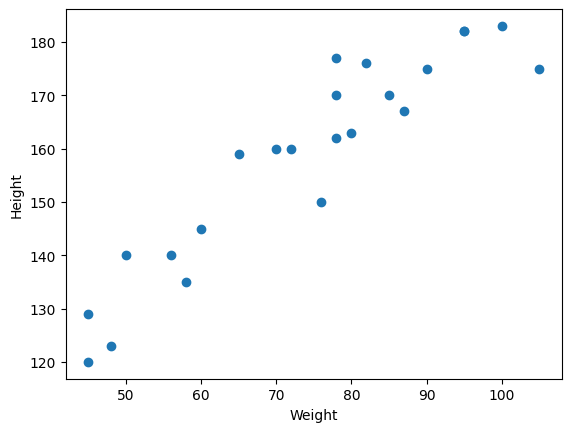

In [5]:
# Scatter plot
plt.scatter(df['Weight'],df['Height'])
plt.xlabel('Weight')
plt.ylabel('Height')

In [6]:
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


In [7]:
# USING SEABORN
import seaborn as sns


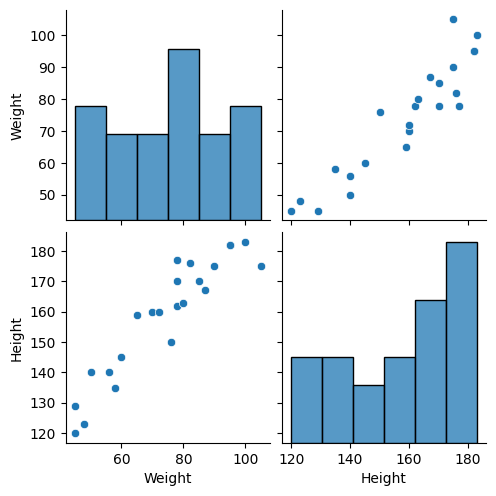

In [8]:
sns.pairplot(df)

In [9]:
x=df['Weight']
type(x)

pandas.core.series.Series

In [10]:
#Always make sure that independent data should be in dataframe
x=df[['Weight']] 
type(x)
x

,Weight
0,45
1,58
2,48
3,60
4,70
5,78
6,80
7,90
8,95
9,78


In [11]:
x=df[['Weight']]
np.array(x).shape

(23, 1)

In [12]:
x=df['Weight']
np.array(x).shape

(23,)

In [13]:
X=df[['Weight']]
y=df[['Height']]

# TRAIN TEST SPLIT

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42)

In [16]:
X_train.shape


(17, 1)

In [17]:
y_train.shape

(17, 1)

In [18]:
# STANDARDIZATION 
from sklearn.preprocessing import StandardScaler

In [19]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)

In [20]:
X_test=scaler.transform(X_test)

In [21]:
X_test

array([[ 0.33497168],
       [ 0.33497168],
       [-1.6641678 ],
       [ 1.36483141],
       [-0.45256812],
       [ 1.97063125]])

In [22]:
# APPLY SIMPLE LINEAR REGRESSION
from sklearn.linear_model import LinearRegression


In [23]:
regression=LinearRegression(n_jobs=-1)

In [24]:
regression.fit(X_train,y_train)

LinearRegression(n_jobs=-1)

In [25]:
print("Coefficient or slope :",regression.coef_)
print("intercept:",regression.intercept_)

Coefficient or slope : [[17.2982057]]
intercept: [156.47058824]


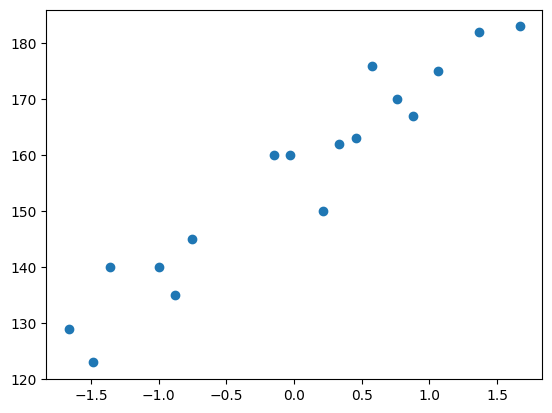

In [26]:
# PLOT TRAINING DATA AND PLOT BEST FIT LINE
plt.scatter(X_train,y_train)

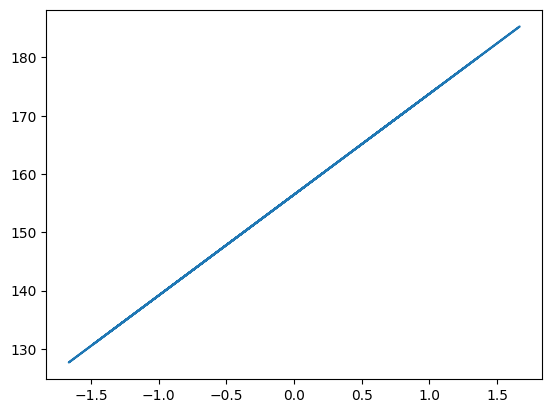

In [27]:
plt.plot(X_train,regression.predict(X_train))

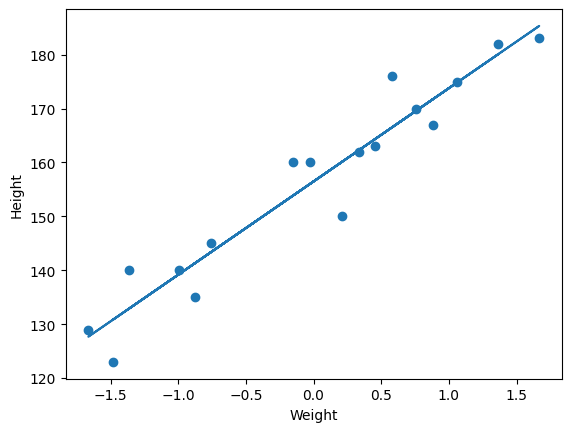

In [28]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regression.predict(X_train))

plt.xlabel("Weight")
plt.ylabel("Height")
plt.show()

In [29]:
# PREDICTION FOR TEST DATA
y_pred=regression.predict(X_test)

In [30]:
# PERFORMANCE MATRIX
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [31]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

114.84069295228699
9.66512588679501
10.716374991212605


In [32]:
# R SQUARED ERROR
from sklearn.metrics import r2_score

In [33]:
score=r2_score(y_test,y_pred)
print(score)

0.7360826717981276


In [34]:
# ADJUSTED R SQUARE
1-(1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.6701033397476595

In [35]:
print(y_test,y_pred)

    Height
15     177
9      170
0      120
8      182
17     159
12     175 [[162.26499721]
 [162.26499721]
 [127.68347133]
 [180.07972266]
 [148.64197186]
 [190.55897293]]


In [36]:
# OLS LINEAR REGRESSION
import statsmodels.api as sm

In [37]:
model=sm.OLS(y_train,X_train).fit()

In [38]:
prediction=model.predict(X_test)
print(prediction)

[  5.79440897   5.79440897 -28.78711691  23.60913442  -7.82861638
  34.08838469]


In [39]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.012
Model:                            OLS   Adj. R-squared (uncentered):             -0.050
Method:                 Least Squares   F-statistic:                             0.1953
Date:                Thu, 08 Oct 2026   Prob (F-statistic):                       0.664
Time:                        18:31:24   Log-Likelihood:                         -110.03
No. Observations:                  17   AIC:                                      222.1
Df Residuals:                      16   BIC:                                      222.9
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [40]:
# PREDICTION FOR NEW DATA
regression.predict(scaler.transform([[72]]))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[155.97744705]])